# EVALUASI FINAL MODEL 5-FOLD - DENSENET121 + GRAD-CAM

## Klasifikasi Tumor Paru pada Citra CT Scan
### Menggunakan DenseNet121 dan Explainable Artificial Intelligence berbasis Grad-CAM

---

## Tujuan Notebook

Evaluasi **final** terhadap model DenseNet121 yang sudah dilatih pada
**5-Fold Cross Validation** (patient-level / group-level split).

Untuk setiap fold, notebook ini:

1. Mengambil **validation set fold tersebut** saja
2. Memuat checkpoint **BEST STAGE 2** fold tersebut
3. Membangun arsitektur DenseNet121 yang **identik** dengan training
4. Memprediksi validation set
5. Menghitung confusion matrix, accuracy, precision, recall, F1, ROC, AUC

## Prinsip yang ditegaskan di notebook ini

| Aturan | Penerapan |
|---|---|
| **Bukan** `val_accuracy` dari history training | Metrik dihitung ulang dari prediksi checkpoint |
| Tidak ada fitting ulang | Model hanya `load_weights()` + `predict()` |
| Tidak ada augmentation pada validation | Validation dimuat apa adanya dari `.npy` |
| Tidak ada oversampling / undersampling | Distribusi kelas validation apa adanya |
| Tidak ada threshold tuning | Threshold tetap **0.5** |
| Tidak ada test set | Penelitian memakai 5-Fold CV, bukan split test tunggal |
| Tidak ada preprocessing kedua | `.npy` sudah keluaran `densenet.preprocess_input` |
| Evaluasi independen per fold | Tidak ada pencampuran validation antar fold |

## Kesetaraan arsitektur

```
DenseNet121(include_top=False, weights="imagenet", input_shape=(224,224,3))
  -> GlobalAveragePooling2D
  -> Dense(1, activation="sigmoid", name="malignancy")
```

Checkpoint: `models/densenet121/fold_k/best_stage2.weights.h5`
(best Stage 2 = bobot dengan `val_loss` terbaik, sesuai `save_best_only=True`).

# 1. Setup Environment

Python 3.12 · TensorFlow 2.21 · WSL2 · NVIDIA RTX 4070.

Sesuai keputusan proyek, **GPU wajib**. Jika GPU tidak terdeteksi, notebook
**berhenti** - tidak ada fallback ke CPU.

In [1]:
# --- CELL 1 - SETUP ENVIRONMENT ------------------------------------------
import os

# TensorFlow harus tahu GPU SEBELUM di-import.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

import json
import random
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# --- SEED (reproducibility; fold assignment TIDAK diubah) ------------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- WAJIB GPU (konsisten dengan notebook training) -----------------------
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError(
        "GPU TIDAK terdeteksi. Evaluasi pada proyek ini WAJIB berjalan di GPU "
        "(konsisten dengan notebook training). Jalankan di WSL2 dengan "
        "NVIDIA RTX 4070 terlihat oleh TensorFlow. PROSES DIHENTIKAN - "
        "tidak ada fallback ke CPU."
    )
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

print("ENVIRONMENT")
print("=" * 74)
print(f"  python           : {platform.python_version()}")
print(f"  tensorflow       : {tf.__version__}")
print(f"  keras            : {tf.keras.__version__}")
print(f"  numpy            : {np.__version__}")
print(f"  pandas           : {pd.__version__}")
print(f"  scikit-learn     : {sklearn.__version__}")
print(f"  matplotlib       : {matplotlib.__version__}")
print(f"  seed             : {SEED}")
print()
print(f"  GPU_COUNT        : {len(gpus)}")
for i, g in enumerate(gpus):
    det = tf.config.experimental.get_device_details(g)
    cc = det.get("compute_capability")
    cap = f"{cc[0]}.{cc[1]}" if cc else "-"
    print(f"  GPU[{i}]            : {g.name}")
    print(f"    device_name    : {det.get('device_name')}")
    print(f"    compute_cap    : {cap}")
print()
print("  [OK] GPU terdeteksi. Notebook lanjut ke konfigurasi.")

I0000 00:00:1791274571.583536   88669 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791274586.207138   88669 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


ENVIRONMENT
  python           : 3.12.13
  tensorflow       : 2.21.0
  keras            : 3.15.1
  numpy            : 2.2.6
  pandas           : 2.2.3
  scikit-learn     : 1.6.1
  matplotlib       : 3.9.4
  seed             : 42

  GPU_COUNT        : 1
  GPU[0]            : /physical_device:GPU:0
    device_name    : NVIDIA GeForce RTX 4070
    compute_cap    : 8.9

  [OK] GPU terdeteksi. Notebook lanjut ke konfigurasi.


# 2. Configuration

Semua path ditulis relatif terhadap project root agar notebook bisa dibuka
dari folder mana pun. Folder output dibuat otomatis.

In [2]:
# --- CELL 2 - KONFIGURASI & PATH -----------------------------------------
MANIFEST_RELPATH = Path("dataset/04_preprocessed/preprocessed_manifest.csv")
FOLDS_RELPATH = Path("dataset/05_splits/fold_assignments.csv")
MODELS_RELDIR = Path("models/densenet121")
EVAL_RELDIR = Path("results/evaluation")
FIG_RELDIR = Path("results/evaluation/figures")
TRAINING_CONFIG_RELPATH = Path("results/training/training_config.json")

N_SPLITS = 5
FOLDS = [1, 2, 3, 4, 5]

# Arsitektur WAJIB identik dengan notebook training.
BACKBONE = "DenseNet121"
INCLUDE_TOP = False
WEIGHTS_INIT = "imagenet"
INPUT_SHAPE = (224, 224, 3)
HEAD_LAYER = "Dense(1, sigmoid)"
FINE_TUNE_LAST_N_LAYERS = 30

# Bobot yang dievaluasi = BEST STAGE 2 setiap fold.
STAGE_EVALUATED = "stage2"
STAGE_LABEL = "Stage 2"          # hanya untuk tampilan
CKPT_NAME = f"best_{STAGE_EVALUATED}.weights.h5"

# Inferensi
BATCH_SIZE = 32
THRESHOLD = 0.5          # default binary classification - TIDAK di-tuning

# Ekspektasi dataset (dipakai untuk assertion)
EXPECTED_TOTAL = 524
EXPECTED_BENIGN = 381
EXPECTED_MALIGNANT = 143

# .npy sudah keluaran densenet.preprocess_input -> JANGAN preprocess lagi.
ALREADY_PREPROCESSED = True


def find_project_root(marker: Path, start: Path | None = None) -> Path:
    base = Path(start).resolve() if start else Path.cwd().resolve()
    for candidate in [base, *base.parents]:
        if (candidate / marker).exists():
            return candidate
    searched = "\n".join(f"  - {p}" for p in [base, *base.parents])
    raise FileNotFoundError(
        f"PROJECT_ROOT tidak ditemukan.\nNotebook mencari: {marker}\n\n"
        f"Direktori yang diperiksa:\n{searched}"
    )


PROJECT_ROOT = find_project_root(MANIFEST_RELPATH)
MANIFEST_FILE = PROJECT_ROOT / MANIFEST_RELPATH
FOLDS_FILE = PROJECT_ROOT / FOLDS_RELPATH
MODELS_DIR = PROJECT_ROOT / MODELS_RELDIR
EVAL_DIR = PROJECT_ROOT / EVAL_RELDIR
FIG_DIR = PROJECT_ROOT / FIG_RELDIR
TRAINING_CONFIG_FILE = PROJECT_ROOT / TRAINING_CONFIG_RELPATH

EVAL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("KONFIGURASI EVALUASI")
print("-" * 74)
print(f"  PROJECT_ROOT    : {PROJECT_ROOT}")
print(f"  Manifest        : {MANIFEST_RELPATH}")
print(f"  Fold assignment : {FOLDS_RELPATH}")
print(f"  Checkpoint      : {MODELS_RELDIR}/fold_k/{CKPT_NAME}")
print(f"  Output          : {EVAL_RELDIR}")
print(f"  Figures         : {FIG_RELDIR}")
print()
print(f"  Folds           : {FOLDS}")
print(f"  Input shape     : {INPUT_SHAPE}")
print(f"  Head            : {HEAD_LAYER}")
print(f"  Fine-tune last  : {FINE_TUNE_LAST_N_LAYERS} layer (kondisi Stage 2)")
print(f"  Batch size      : {BATCH_SIZE}")
print(f"  Threshold       : {THRESHOLD}  (default, tanpa tuning)")
print(f"  Preprocessed    : {ALREADY_PREPROCESSED} "
      f"(JANGAN panggil preprocess_input lagi)")

KONFIGURASI EVALUASI
--------------------------------------------------------------------------
  PROJECT_ROOT    : /mnt/c/230016_rivan/source-code2020
  Manifest        : dataset/04_preprocessed/preprocessed_manifest.csv
  Fold assignment : dataset/05_splits/fold_assignments.csv
  Checkpoint      : models/densenet121/fold_k/best_stage2.weights.h5
  Output          : results/evaluation
  Figures         : results/evaluation/figures

  Folds           : [1, 2, 3, 4, 5]
  Input shape     : (224, 224, 3)
  Head            : Dense(1, sigmoid)
  Fine-tune last  : 30 layer (kondisi Stage 2)
  Batch size      : 32
  Threshold       : 0.5  (default, tanpa tuning)
  Preprocessed    : True (JANGAN panggil preprocess_input lagi)


# 3. Load Dataset Manifest dan Fold Assignment

Sumber data ada dua, dan keduanya harus **konsisten**:

| File | Peran |
|---|---|
| `dataset/04_preprocessed/preprocessed_manifest.csv` | Sumber training: berisi `PreprocessedPath` (path `.npy`), `Fold`, `LabelBinary` |
| `dataset/05_splits/fold_assignments.csv` | Sumber split: pemetaan resmi `NoduleClusterID -> Fold` |

Manifest preprocessed adalah sumber utama (sama seperti di notebook training).
Fold assignment dipakai sebagai **verifikasi silang**: jika ada
`NoduleClusterID` yang memiliki nilai `Fold` berbeda di kedua file, berarti ada
ketidakkonsistenan data dan proses dihentikan.

In [3]:
# --- CELL 3 - LOAD MANIFEST + FOLD ASSIGNMENT ------------------------------
man = pd.read_csv(MANIFEST_FILE, dtype={
    "PatientID": str,
    "SeriesInstanceUID": str,
    "NoduleClusterID": str,
})
folds_df = pd.read_csv(FOLDS_FILE, dtype={
    "PatientID": str,
    "SeriesInstanceUID": str,
    "NoduleClusterID": str,
})

print("LOAD DATASET")
print("=" * 74)
print(f"  preprocessed_manifest.csv : {len(man)} baris, {man.shape[1]} kolom")
print(f"  fold_assignments.csv      : {len(folds_df)} baris, {folds_df.shape[1]} kolom")
print()
print(f"  PatientID unik  : {man.PatientID.nunique()}")
print(f"  SeriesInstance  : {man.SeriesInstanceUID.nunique()}")
print(f"  NoduleClusterID : {man.NoduleClusterID.nunique()} unik")
print(f"  Label (teks)    : {sorted(man.Label.unique().tolist())}")
print(f"  LabelBinary     : {sorted(man.LabelBinary.unique().tolist())}")

# --- verifikasi silang fold assignment vs manifest ------------------------
fa = folds_df.set_index("NoduleClusterID")["Fold"]
mm = man.set_index("NoduleClusterID")["Fold"]
common = mm.index.intersection(fa.index)
mismatch = common[mm.loc[common].to_numpy() != fa.loc[common].to_numpy()]
print()
print(f"  NoduleClusterID di kedua file : {len(common)}")
print(f"  Selisih nilai Fold            : {len(mismatch)}")
if len(mismatch):
    raise ValueError(
        f"Fold assignment tidak konsisten dengan manifest pada "
        f"{len(mismatch)} NoduleClusterID: {list(mismatch[:5])}. "
        "PROSES DIHENTIKAN."
    )
print("  [OK] Fold assignment konsisten dengan manifest training")

# --- ringkasan fold --------------------------------------------------------
per_fold = (
    man.groupby("Fold")
       .agg(N=("LabelBinary", "size"),
            N_benign=("LabelBinary", lambda s: int((s == 0).sum())),
            N_malignant=("LabelBinary", lambda s: int((s == 1).sum())),
            N_pasien=("PatientID", "nunique"))
       .reindex(FOLDS)
)
print()
print("  Distribusi per fold (setiap baris = validation set fold tersebut):")
print(per_fold.to_string())
print()
print(f"  TOTAL N = {int(per_fold.N.sum())}")

LOAD DATASET
  preprocessed_manifest.csv : 524 baris, 38 kolom
  fold_assignments.csv      : 524 baris, 7 kolom

  PatientID unik  : 225
  SeriesInstance  : 225
  NoduleClusterID : 524 unik
  Label (teks)    : ['Benign', 'Malignant']
  LabelBinary     : [0, 1]

  NoduleClusterID di kedua file : 524
  Selisih nilai Fold            : 0
  [OK] Fold assignment konsisten dengan manifest training

  Distribusi per fold (setiap baris = validation set fold tersebut):
        N  N_benign  N_malignant  N_pasien
Fold                                      
1      82        57           25        40
2     126        94           32        47
3     106        74           32        46
4      97        69           28        45
5     113        87           26        47

  TOTAL N = 524


# 4. Sanity Check Dataset

Semua pemeriksaan dijalankan **sebelum** evaluasi. Jika ada yang gagal, notebook
berhenti - tidak ada sample yang dibuang atau diperbaiki diam-diam.

Yang diperiksa:

- 5 checkpoint tersedia
- manifest dan fold assignment tersedia
- total sample = 524 (381 benign / 143 malignant)
- tidak ada `NoduleClusterID` duplikat
- tidak ada sample validation yang muncul di fold lain
- label hanya 0 dan 1
- file `.npy`: shape `(224,224,3)`, dtype `float32`, tanpa NaN/Inf

In [4]:
# --- CELL 4 - SANITY CHECK -------------------------------------------------
problems = []


def check(condition: bool, message: str) -> None:
    status = "OK  " if condition else "GAGAL"
    print(f"  [{status}] {message}")
    if not condition:
        problems.append(message)


print("SANITY CHECK")
print("=" * 74)

# --- 1. file sumber ada ---------------------------------------------------
check(MANIFEST_FILE.is_file(), f"manifest tersedia: {MANIFEST_RELPATH}")
check(FOLDS_FILE.is_file(), f"fold assignment tersedia: {FOLDS_RELPATH}")

# --- 2. checkpoint 5 fold tersedia ----------------------------------------
print()
missing_ckpt = []
for k in FOLDS:
    ck = MODELS_DIR / f"fold_{k}" / CKPT_NAME
    if not ck.is_file():
        missing_ckpt.append(str(ck.relative_to(PROJECT_ROOT)))
check(not missing_ckpt,
      f"checkpoint {CKPT_NAME} tersedia untuk fold {FOLDS[0]}..{FOLDS[-1]}"
      + (f" - HILANG: {missing_ckpt}" if missing_ckpt else ""))

# --- 3. jumlah sample & distribusi label ----------------------------------
print()
check(len(man) == EXPECTED_TOTAL,
      f"jumlah sample = {len(man)} (harus {EXPECTED_TOTAL})")
n_benign = int((man.LabelBinary == 0).sum())
n_malignant = int((man.LabelBinary == 1).sum())
check(n_benign == EXPECTED_BENIGN, f"benign = {n_benign} (harus {EXPECTED_BENIGN})")
check(n_malignant == EXPECTED_MALIGNANT,
      f"malignant = {n_malignant} (harus {EXPECTED_MALIGNANT})")

# --- 4. tidak ada duplikat -------------------------------------------------
print()
dup = int(man.NoduleClusterID.duplicated().sum())
check(dup == 0, f"tidak ada NoduleClusterID duplikat (duplikat = {dup})")

# --- 5. label hanya 0 dan 1 -----------------------------------------------
check(set(man.LabelBinary.unique()) <= {0, 1},
      f"LabelBinary hanya berisi 0 dan 1: {sorted(man.LabelBinary.unique().tolist())}")

# --- 6. fold assignment valid & lengkap ------------------------------------
print()
check(set(man.Fold.unique()) == set(FOLDS),
      f"Fold berisi 1..5: {sorted(man.Fold.unique().tolist())}")

# --- 7. tidak ada sample validation yang muncul di fold lain ---------------
per_fold_counts = man.Fold.value_counts().reindex(FOLDS).fillna(0).astype(int)
check(bool((per_fold_counts > 0).all()),
      f"setiap fold punya validation sample: {per_fold_counts.to_dict()}")
check(int(per_fold_counts.sum()) == EXPECTED_TOTAL,
      f"total sample di 5 validation set = {int(per_fold_counts.sum())} "
      f"(harus {EXPECTED_TOTAL})")
check(bool(man.PatientID.nunique() == 225),
      f"jumlah pasien = {man.PatientID.nunique()} (grouping by PatientID)")

# --- 8. file .npy: shape / dtype / NaN / Inf -------------------------------
print()
bad = {"missing": [], "shape": [], "dtype": [], "nan": [], "inf": []}
for _, r in man.iterrows():
    p = PROJECT_ROOT / r.PreprocessedPath
    if not p.is_file():
        bad["missing"].append(str(r.NoduleClusterID))
        continue
    arr = np.load(p)
    if arr.shape != INPUT_SHAPE:
        bad["shape"].append((str(r.NoduleClusterID), arr.shape))
    if arr.dtype != np.float32:
        bad["dtype"].append((str(r.NoduleClusterID), str(arr.dtype)))
    if np.isnan(arr).any():
        bad["nan"].append(str(r.NoduleClusterID))
    if np.isinf(arr).any():
        bad["inf"].append(str(r.NoduleClusterID))

for k, v in bad.items():
    check(not v, f"file .npy bermasalah '{k}' = {len(v)}" + (f" {v[:3]}" if v else ""))

check(all(len(v) == 0 for v in bad.values()),
      f"seluruh {len(man)} file .npy: shape {INPUT_SHAPE}, float32, tanpa NaN/Inf")
print()
print(f"  Rentang nilai input (hasil densenet.preprocess_input): "
      f"{man.ModelInputMin.min():.3f} .. {man.ModelInputMax.max():.3f}")
print("  Catatan: nilai di luar [0, 1] itu NORMAL. Preprocessing SUDAH_apply.")

# --- 9. hasil akhir -------------------------------------------------------
if problems:
    raise ValueError(
        f"Sanity check gagal ({len(problems)} masalah). PROSES DIHENTIKAN:\n  - "
        + "\n  - ".join(problems)
    )

print()
print("=" * 74)
print(f"[OK] SANITY CHECK LOLOS - {len(man)} sample siap dievaluasi per fold.")

SANITY CHECK
  [OK  ] manifest tersedia: dataset/04_preprocessed/preprocessed_manifest.csv
  [OK  ] fold assignment tersedia: dataset/05_splits/fold_assignments.csv

  [OK  ] checkpoint best_stage2.weights.h5 tersedia untuk fold 1..5

  [OK  ] jumlah sample = 524 (harus 524)
  [OK  ] benign = 381 (harus 381)
  [OK  ] malignant = 143 (harus 143)

  [OK  ] tidak ada NoduleClusterID duplikat (duplikat = 0)
  [OK  ] LabelBinary hanya berisi 0 dan 1: [0, 1]

  [OK  ] Fold berisi 1..5: [1, 2, 3, 4, 5]
  [OK  ] setiap fold punya validation sample: {1: 82, 2: 126, 3: 106, 4: 97, 5: 113}
  [OK  ] total sample di 5 validation set = 524 (harus 524)
  [OK  ] jumlah pasien = 225 (grouping by PatientID)

  [OK  ] file .npy bermasalah 'missing' = 0
  [OK  ] file .npy bermasalah 'shape' = 0
  [OK  ] file .npy bermasalah 'dtype' = 0
  [OK  ] file .npy bermasalah 'nan' = 0
  [OK  ] file .npy bermasalah 'inf' = 0
  [OK  ] seluruh 524 file .npy: shape (224, 224, 3), float32, tanpa NaN/Inf

  Rentang nilai

# 5. Define DenseNet121 Architecture

Arsitektur **harus identik** dengan notebook training, kalau tidak bobot tidak
akan cocok:

```
DenseNet121(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
  -> GlobalAveragePooling2D()
  -> Dense(1, activation="sigmoid", name="malignancy")
```

Dua hal yang perlu diperhatikan:

1. **Bobot ImageNet hanya untuk membangun *bentuk* jaringan.** Setelah itu
   `load_weights()` menimpa **seluruh** bobot layer (backbone + head) dari
   checkpoint, jadi nilai ImageNet tidak lagi berperan saat evaluasi.
2. **Model sengaja tidak di-`compile()`.** Notebook ini hanya inferensi; tidak
   ada `fit()` dan tidak ada optimizer yang dibutuhkan. Menghilangkan
   `compile()` juga menghilangkan warning Keras tentang optimizer state.

Jumlah parameter akan dibandingkan dengan `results/training/training_config.json`
sebagai bukti arsitektur benar-benar identik.

In [5]:
# --- CELL 5 - ARSITEKTUR DENSENET121 (IDENTIK DENGAN TRAINING) ----------
def build_eval_model(fine_tune_last_n: int = FINE_TUNE_LAST_N_LAYERS) -> tf.keras.Model:
    """Bangun DenseNet121 + head, identik dengan notebook training.

    fine_tune_last_n = 30 -> meniru kondisi Stage 2 (30 layer terakhir terbuka).
    Nilai ini hanya memengaruhi flag `trainable`, bukan bentuk bobot, jadi
    `load_weights()` tetap cocok dengan checkpoint best_stage2.

    Sengaja TIDAK compile(): evaluasi hanya butuh forward pass.
    """
    base = tf.keras.applications.DenseNet121(
        include_top=INCLUDE_TOP,
        weights=WEIGHTS_INIT,
        input_shape=INPUT_SHAPE,
    )

    # sama dengan train_stage(..., stage="stage2", fine_tune_last_n=30)
    base.trainable = True
    for layer in base.layers[:-fine_tune_last_n]:
        layer.trainable = False

    model = tf.keras.Sequential([
        base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(1, activation="sigmoid", name="malignancy"),
    ], name="densenet121_lidc")
    return model


print("ARSITEKTUR MODEL")
print("=" * 74)
print(f"  Backbone        : {BACKBONE}")
print(f"  include_top     : {INCLUDE_TOP}")
print(f"  weights (init)  : {WEIGHTS_INIT}  (digantikan load_weights di bawah)")
print(f"  input_shape     : {INPUT_SHAPE}")
print(f"  Head            : GlobalAveragePooling2D -> {HEAD_LAYER}")
print(f"  compile()       : TIDAK (inferensi saja, tanpa fit)")
print()

probe = build_eval_model(FINE_TUNE_LAST_N_LAYERS)
TOTAL_PARAMS = probe.count_params()
TRAINABLE_PARAMS = sum(int(np.prod(w.shape)) for w in probe.trainable_weights)

print(f"  total parameter : {TOTAL_PARAMS:,}")
print(f"  trainable       : {TRAINABLE_PARAMS:,}")
print(f"  frozen          : {TOTAL_PARAMS - TRAINABLE_PARAMS:,}")
print()

# Bandingkan dengan training_config.json -> bukti arsitektur identik.
if TRAINING_CONFIG_FILE.is_file():
    tc = json.loads(TRAINING_CONFIG_FILE.read_text(encoding="utf-8"))
    ref_total = tc["model"]["total_params_stage1"]
    same = TOTAL_PARAMS == ref_total
    print(f"  training_config total_params_stage1 : {ref_total:,}")
    print(f"  [ {'OK ' if same else 'GAGAL'} ] jumlah parameter identik dengan "
          f"training ({TOTAL_PARAMS:,} == {ref_total:,})")
    if not same:
        raise ValueError(
            f"Jumlah parameter evaluasi ({TOTAL_PARAMS:,}) tidak sama dengan "
            f"training ({ref_total:,}). Arsitektur TIDAK identik. PROSES DIHENTIKAN."
        )

assert TRAINABLE_PARAMS == 642_433, (
    f"trainable params harus 642.433 (kondisi Stage 2), dapat {TRAINABLE_PARAMS:,}")

print("  [OK ] 642.433 trainable params = kondisi Stage 2 (30 layer terakhir)")
print("  [OK ] layer Dense(1) bernama 'malignancy' sama dengan checkpoint training")
print()
print("  Model probe dibuang; akan dibangun ulang per fold saat load checkpoint.")

ARSITEKTUR MODEL
  Backbone        : DenseNet121
  include_top     : False
  weights (init)  : imagenet  (digantikan load_weights di bawah)
  input_shape     : (224, 224, 3)
  Head            : GlobalAveragePooling2D -> Dense(1, sigmoid)
  compile()       : TIDAK (inferensi saja, tanpa fit)

  total parameter : 7,038,529
  trainable       : 642,433
  frozen          : 6,396,096

  training_config total_params_stage1 : 7,038,529
  [ OK  ] jumlah parameter identik dengan training (7,038,529 == 7,038,529)
  [OK ] 642.433 trainable params = kondisi Stage 2 (30 layer terakhir)
  [OK ] layer Dense(1) bernama 'malignancy' sama dengan checkpoint training

  Model probe dibuang; akan dibangun ulang per fold saat load checkpoint.


# 6. Evaluation Functions

Tiga kelompok fungsi:

| Fungsi | Tugas |
|---|---|
| `load_validation_arrays(fold)` | Muat `.npy` validation set fold tersebut, apa adanya |
| `safe_div` / `compute_metrics` | Hitung metrik dengan perlindungan zero-division |
| `evaluate_fold(fold)` | Bangun model -> load checkpoint -> predict -> metrik |

Catatan penting:

- **Tanpa `tf.data` pada validation.** Data dibaca langsung dengan `np.load`
  lalu di-`stack`, sehingga tidak ada `shuffle`, tidak ada `augmentation`, dan
  urutan sample pasti sama dengan urutan baris manifest - mudah diaudit.
- **Tanpa `compile()`**, jadi `predict()` tidak mungkin melakukan fitting.
- **Probability disimpan** untuk ROC-AUC; threshold 0.5 hanya dipakai untuk
  Accuracy, Precision, Recall, dan F1.
- Setiap metrik dihitung **dua kali**: rumus eksplisit (aman zero-division)
  dan `sklearn.metrics`. Keduanya harus cocok, dan itu di-`assert`.

## Catatan tentang warning TensorFlow

Saat menjalankan cell ini bisa muncul warning seperti:

```
WARNING:tensorflow:5 out of the last 8 calls to <...one_step_on_data_distributed...>
triggered tf.function retracing.
```

Warning ini **benign** dan **tidak memengaruhi hasil**:

- Penyebabnya adalah `predict()` dipecah jadi beberapa batch, dan batch terakhir
  tiap fold punya ukuran berbeda (mis. 126 sample -> 32+32+32+30), sehingga
  TensorFlow membuat ulang `tf.function` untuk bentuk input yang baru.
- Tidak ada dropout atau augmentasi saat inferensi, jadi predsi sepenuhnya
  deterministik.
- Efeknya hanya pada kecepatan trace, bukan pada nilai probability.

Warning ini muncul juga di notebook training, dan tidak muncul sebagai error
di notebook ini.

In [6]:
# --- CELL 6 - FUNGSI EVALUASI ---------------------------------------------
FOLD_RESULTS: dict[int, dict] = {}


def safe_div(num: float, den: float) -> float:
    """Pembagian aman: kembalikan 0.0 bila penyebut 0 (hindari ZeroDivisionError)."""
    den = float(den)
    return float(num) / den if den != 0.0 else 0.0


def load_validation_arrays(fold: int):
    """Muat validation set satu fold. TANPA augmentasi, TANPA shuffle."""
    sub = man[man.Fold == fold].copy()
    if sub.empty:
        raise ValueError(f"Fold {fold} tidak punya validation sample")

    # np.stack mempertahankan urutan baris manifest
    xs = np.stack([np.load(PROJECT_ROOT / p) for p in sub.PreprocessedPath])
    xs = np.asarray(xs, dtype=np.float32)
    y_true = sub.LabelBinary.to_numpy().astype(np.int32)

    assert xs.shape[1:] == INPUT_SHAPE, f"shape tidak sesuai: {xs.shape}"
    assert xs.dtype == np.float32, f"dtype tidak sesuai: {xs.dtype}"
    assert np.isfinite(xs).all(), "ada NaN/Inf pada input"
    return sub, xs, y_true


def compute_metrics(y_true, y_prob, threshold: float = THRESHOLD) -> dict:
    """Hitung seluruh metrik untuk satu fold.

    y_true    : label aktual 0/1
    y_prob    : probability Malignant (float, [0,1]) -> dipakai untuk ROC-AUC
    threshold : 0.5, tanpa tuning
    """
    y_true = np.asarray(y_true, dtype=np.int32).ravel()
    y_prob = np.asarray(y_prob, dtype=np.float64).ravel()

    # class prediction dari threshold default
    y_pred = (y_prob >= threshold).astype(np.int32)

    # --- confusion matrix dengan definisi eksplisit ---------------------
    # baris = Actual, kolom = Predicted  ->  [[TN, FP], [FN, TP]]
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp = int(cm[0, 0]), int(cm[0, 1])
    fn, tp = int(cm[1, 0]), int(cm[1, 1])

    # --- rumus eksplisit (aman zero division) ---------------------------
    acc_m = safe_div(tp + tn, tp + tn + fp + fn)
    prec_m = safe_div(tp, tp + fp)
    rec_m = safe_div(tp, tp + fn)
    f1_m = safe_div(2 * prec_m * rec_m, prec_m + rec_m)

    # --- sklearn.metrics (sumber utama) ---------------------------------
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)

    # AUC hanya bisa dihitung bila validation set punya kedua kelas
    auc = float(roc_auc_score(y_true, y_prob)) \
        if len(np.unique(y_true)) > 1 else float("nan")

    # --- sanity: sklearn harus cocok dengan rumus manual ------------------
    assert np.isclose(acc, acc_m), f"accuracy sklearn {acc} != manual {acc_m}"
    assert np.isclose(prec, prec_m), f"precision sklearn {prec} != manual {prec_m}"
    assert np.isclose(rec, rec_m), f"recall sklearn {rec} != manual {rec_m}"
    assert np.isclose(f1, f1_m), f"f1 sklearn {f1} != manual {f1_m}"

    # --- sanity: panjang & rentang probability ----------------------------
    assert len(y_true) == len(y_pred) == len(y_prob), "panjang tidak konsisten"
    assert np.isfinite(y_prob).all(), "ada probability NaN/Inf"
    assert (y_prob >= 0.0).all() and (y_prob <= 1.0).all(), \
        "probability di luar rentang [0, 1]"

    return {
        "N": int(len(y_true)),
        "N_benign": int((y_true == 0).sum()),
        "N_malignant": int((y_true == 1).sum()),
        "threshold": float(threshold),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": float(acc),
        "Precision": float(prec),
        "Recall": float(rec),
        "F1": float(f1),
        "ROC_AUC": auc,
        "confusion_matrix": cm,
        "fpr": fpr,
        "tpr": tpr,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
    }


def evaluate_fold(fold: int) -> dict:
    """Evaluasi INDEPENDEN satu fold pada validation set fold tersebut."""
    print("=" * 74)
    print(f"FOLD {fold} - EVALUASI BEST {STAGE_LABEL.upper()}")
    print("=" * 74)

    # --- validation set fold ini saja (TIDAK boleh dicampur) -------------
    sub, xs, y_true = load_validation_arrays(fold)
    print(f"  validation set : {len(sub)} sample dari "
          f"{sub.PatientID.nunique()} pasien")
    print(f"    benign (0)    : {int((y_true == 0).sum())}")
    print(f"    malignant (1) : {int((y_true == 1).sum())}")
    print("  augmentasi     : TIDAK")
    print("  shuffle        : TIDAK")

    # --- bangun model + load checkpoint fold ini -------------------------
    ckpt = MODELS_DIR / f"fold_{fold}" / CKPT_NAME
    model = build_eval_model(FINE_TUNE_LAST_N_LAYERS)
    model.load_weights(str(ckpt))
    print(f"  checkpoint     : {ckpt.relative_to(PROJECT_ROOT)}")
    print(f"  load_weights   : OK ({model.count_params():,} parameter)")

    # --- prediksi ---------------------------------------------------------
    y_prob = model.predict(xs, batch_size=BATCH_SIZE, verbose=0).ravel()
    del model  # bebaskan VRAM sebelum fold berikutnya

    # --- metrik -----------------------------------------------------------
    res = compute_metrics(y_true, y_prob, threshold=THRESHOLD)
    res["fold"] = int(fold)
    res["checkpoint"] = str(ckpt.relative_to(PROJECT_ROOT))
    res["sub"] = sub

    print()
    print(f"  Accuracy  : {res['Accuracy']:.4f}")
    print(f"  Precision : {res['Precision']:.4f}")
    print(f"  Recall    : {res['Recall']:.4f}")
    print(f"  F1-Score  : {res['F1']:.4f}")
    print(f"  ROC-AUC   : {res['ROC_AUC']:.4f}")
    print()
    print("  Confusion matrix (baris=Actual, kolom=Predicted)")
    print("               benign   malignant")
    print(f"    benign     {res['TN']:>7}   {res['FP']:>8}")
    print(f"    malignant  {res['FN']:>7}   {res['TP']:>8}")

    FOLD_RESULTS[fold] = res
    return res


def print_fold_report(fold: int, res: dict) -> None:
    print(f"Fold {fold}: N samples = {res['N']} "
          f"(benign {res['N_benign']}, malignant {res['N_malignant']}, "
          f"pasien {res['sub'].PatientID.nunique()})")


def save_cm_figure(fold: int, res: dict) -> Path:
    """Simpan confusion matrix satu fold."""
    cm = res["confusion_matrix"]
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks([0, 1], labels=["Benign", "Malignant"])
    ax.set_yticks([0, 1], labels=["Benign", "Malignant"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"Confusion Matrix - Fold {fold} (best {STAGE_LABEL})\n"
                 f"N = {res['N']}   Accuracy = {res['Accuracy']:.4f}")

    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            ax.text(j, i, f"{val}", ha="center", va="center",
                    fontsize=15, fontweight="bold",
                    color="white" if val > cm.max() / 2 else "#1a1a1a")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    path = FIG_DIR / f"confusion_matrix_fold_{fold}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return path


print("FUNGSI EVALUASI SIAP")
print("-" * 74)
print("  load_validation_arrays : validation fold X, tanpa augmentasi")
print("  safe_div               : pembagian aman zero-division")
print("  compute_metrics        : CM + accuracy/precision/recall/F1 + ROC/AUC")
print("  evaluate_fold          : load checkpoint fold X -> predict -> metrik")
print("  print_fold_report      : ringkasan N sample per fold")
print("  save_cm_figure         : simpan confusion matrix per fold")

FUNGSI EVALUASI SIAP
--------------------------------------------------------------------------
  load_validation_arrays : validation fold X, tanpa augmentasi
  safe_div               : pembagian aman zero-division
  compute_metrics        : CM + accuracy/precision/recall/F1 + ROC/AUC
  evaluate_fold          : load checkpoint fold X -> predict -> metrik
  print_fold_report      : ringkasan N sample per fold
  save_cm_figure         : simpan confusion matrix per fold


# 7. Evaluate Fold 1

Checkpoint `fold_1/best_stage2.weights.h5` (dilatih dengan validation = 82 sample, 40 pasien).

Aturan yang dijaga di cell ini:

- Hanya validation sample milik fold 1
- Tidak ada `fit()` / fitting ulang
- Tidak ada augmentation
- Threshold tetap **0.5**

In [7]:
# --- CELL 7 - EVALUASI FOLD 1 --------------------------------------
R1 = evaluate_fold(1)
print_fold_report(1, R1)

FOLD 1 - EVALUASI BEST STAGE 2
  validation set : 82 sample dari 40 pasien
    benign (0)    : 57
    malignant (1) : 25
  augmentasi     : TIDAK
  shuffle        : TIDAK
  checkpoint     : models/densenet121/fold_1/best_stage2.weights.h5
  load_weights   : OK (7,038,529 parameter)

  Accuracy  : 0.8780
  Precision : 0.7778
  Recall    : 0.8400
  F1-Score  : 0.8077
  ROC-AUC   : 0.9298

  Confusion matrix (baris=Actual, kolom=Predicted)
               benign   malignant
    benign          51          6
    malignant        4         21
Fold 1: N samples = 82 (benign 57, malignant 25, pasien 40)


# 8. Evaluate Fold 2

Checkpoint `fold_2/best_stage2.weights.h5`. Validation set **tidak boleh** dicampur dengan fold 1.

Aturan yang dijaga di cell ini:

- Hanya validation sample milik fold 2
- Tidak ada `fit()` / fitting ulang
- Tidak ada augmentation
- Threshold tetap **0.5**

In [8]:
# --- CELL 8 - EVALUASI FOLD 2 --------------------------------------
R2 = evaluate_fold(2)
print_fold_report(2, R2)

FOLD 2 - EVALUASI BEST STAGE 2
  validation set : 126 sample dari 47 pasien
    benign (0)    : 94
    malignant (1) : 32
  augmentasi     : TIDAK
  shuffle        : TIDAK
  checkpoint     : models/densenet121/fold_2/best_stage2.weights.h5
  load_weights   : OK (7,038,529 parameter)

  Accuracy  : 0.7778
  Precision : 0.5435
  Recall    : 0.7812
  F1-Score  : 0.6410
  ROC-AUC   : 0.8733

  Confusion matrix (baris=Actual, kolom=Predicted)
               benign   malignant
    benign          73         21
    malignant        7         25
Fold 2: N samples = 126 (benign 94, malignant 32, pasien 47)


# 9. Evaluate Fold 3

Checkpoint `fold_3/best_stage2.weights.h5`. Validation set tetap independen dari fold lain.

Aturan yang dijaga di cell ini:

- Hanya validation sample milik fold 3
- Tidak ada `fit()` / fitting ulang
- Tidak ada augmentation
- Threshold tetap **0.5**

In [9]:
# --- CELL 9 - EVALUASI FOLD 3 --------------------------------------
R3 = evaluate_fold(3)
print_fold_report(3, R3)

FOLD 3 - EVALUASI BEST STAGE 2
  validation set : 106 sample dari 46 pasien
    benign (0)    : 74
    malignant (1) : 32
  augmentasi     : TIDAK
  shuffle        : TIDAK
  checkpoint     : models/densenet121/fold_3/best_stage2.weights.h5
  load_weights   : OK (7,038,529 parameter)

  Accuracy  : 0.8113
  Precision : 0.6875
  Recall    : 0.6875
  F1-Score  : 0.6875
  ROC-AUC   : 0.8505

  Confusion matrix (baris=Actual, kolom=Predicted)
               benign   malignant
    benign          64         10
    malignant       10         22
Fold 3: N samples = 106 (benign 74, malignant 32, pasien 46)


# 10. Evaluate Fold 4

Checkpoint `fold_4/best_stage2.weights.h5`. Validation set tetap independen dari fold lain.

Aturan yang dijaga di cell ini:

- Hanya validation sample milik fold 4
- Tidak ada `fit()` / fitting ulang
- Tidak ada augmentation
- Threshold tetap **0.5**

In [10]:
# --- CELL 10 - EVALUASI FOLD 4 --------------------------------------
R4 = evaluate_fold(4)
print_fold_report(4, R4)

FOLD 4 - EVALUASI BEST STAGE 2
  validation set : 97 sample dari 45 pasien
    benign (0)    : 69
    malignant (1) : 28
  augmentasi     : TIDAK
  shuffle        : TIDAK
  checkpoint     : models/densenet121/fold_4/best_stage2.weights.h5
  load_weights   : OK (7,038,529 parameter)

  Accuracy  : 0.8454
  Precision : 0.7097
  Recall    : 0.7857
  F1-Score  : 0.7458
  ROC-AUC   : 0.9234

  Confusion matrix (baris=Actual, kolom=Predicted)
               benign   malignant
    benign          60          9
    malignant        6         22
Fold 4: N samples = 97 (benign 69, malignant 28, pasien 45)


# 11. Evaluate Fold 5

Checkpoint `fold_5/best_stage2.weights.h5`. Validation set tetap independen dari fold lain.

Aturan yang dijaga di cell ini:

- Hanya validation sample milik fold 5
- Tidak ada `fit()` / fitting ulang
- Tidak ada augmentation
- Threshold tetap **0.5**

In [11]:
# --- CELL 11 - EVALUASI FOLD 5 --------------------------------------
R5 = evaluate_fold(5)
print_fold_report(5, R5)

FOLD 5 - EVALUASI BEST STAGE 2
  validation set : 113 sample dari 47 pasien
    benign (0)    : 87
    malignant (1) : 26
  augmentasi     : TIDAK
  shuffle        : TIDAK
  checkpoint     : models/densenet121/fold_5/best_stage2.weights.h5
  load_weights   : OK (7,038,529 parameter)

  Accuracy  : 0.9204
  Precision : 0.8148
  Recall    : 0.8462
  F1-Score  : 0.8302
  ROC-AUC   : 0.9549

  Confusion matrix (baris=Actual, kolom=Predicted)
               benign   malignant
    benign          82          5
    malignant        4         22
Fold 5: N samples = 113 (benign 87, malignant 26, pasien 47)


# 12. Per-Fold Metrics

Tabel utama dari evaluasi. Semua angka **dihitung ulang** dari prediksi
checkpoint, bukan diambil dari `val_accuracy` history training.

> Catatan: `val_accuracy` di `results/training/training_history_fold_*.csv`
> berasal dari model pada akhir epoch, sebelum bobot epoch terbaik dimuat
> kembali oleh `restore_best_weights`. Angka di tabel ini adalah performa akhir
> model terbaik pada data validasi yang sama - keduanya boleh berbeda tipis.

In [12]:
# --- CELL 12 - TABEL METRIK PER FOLD --------------------------------------
def build_fold_metrics_df(results: dict) -> pd.DataFrame:
    rows = []
    for k in FOLDS:
        r = results[k]
        rows.append({
            "Fold": k,
            "N": r["N"],
            "N_benign": r["N_benign"],
            "N_malignant": r["N_malignant"],
            "TN": r["TN"], "FP": r["FP"], "FN": r["FN"], "TP": r["TP"],
            "Threshold": r["threshold"],
            "Accuracy": r["Accuracy"],
            "Precision": r["Precision"],
            "Recall": r["Recall"],
            "F1": r["F1"],
            "ROC_AUC": r["ROC_AUC"],
            "Checkpoint": r["checkpoint"],
        })
    return pd.DataFrame(rows).sort_values("Fold").reset_index(drop=True)


fold_metrics = build_fold_metrics_df(FOLD_RESULTS)

print("METRIK PER FOLD")
print("=" * 74)
display_cols = ["Fold", "N", "N_benign", "N_malignant",
                "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
disp = fold_metrics[display_cols].copy()
for c in ("Accuracy", "Precision", "Recall", "F1", "ROC_AUC"):
    disp[c] = disp[c].map(lambda v: f"{v:.4f}")
print(disp.to_string(index=False))

print()
print(f"Total sample dievaluasi : {int(fold_metrics.N.sum())}")
assert int(fold_metrics.N.sum()) == EXPECTED_TOTAL, \
    f"total harus {EXPECTED_TOTAL}, dapat {int(fold_metrics.N.sum())}"
print(f"[OK] Konfirmasi: {EXPECTED_TOTAL} sample, masing-masing menjadi "
      f"validation tepat satu kali.")

# --- sanity: setiap fold menghasilkan metrik yang lengkap ------------------
print()
for k in FOLDS:
    r = FOLD_RESULTS[k]
    assert r["N"] > 0, f"fold {k} tidak punya sample"
    assert len(r["y_true"]) == len(r["y_pred"]) == len(r["y_prob"]) == r["N"], \
        f"fold {k}: panjang y_true/y_pred/probability tidak sama"
    assert not np.isnan(r["ROC_AUC"]), f"fold {k}: AUC tidak bisa dihitung"
    assert r["N_benign"] > 0 and r["N_malignant"] > 0, \
        f"fold {k}: validation set harus punya kedua kelas"
    print(f"  [OK] Fold {k}: N={r['N']}, "
          f"len(y_true)=len(y_pred)=len(prob)={r['N']}, AUC bisa dihitung")

# --- sanity: tidak ada sample validation yang muncul di fold lain ----------
print()
concat_ids = pd.concat([FOLD_RESULTS[k]["sub"].NoduleClusterID for k in FOLDS])
print(f"  gabungan validation set : {len(concat_ids)} baris, "
      f"{concat_ids.nunique()} unik")
assert len(concat_ids) == concat_ids.nunique() == EXPECTED_TOTAL
print("  [OK] Tidak ada sample yang dipakai di dua fold.")

METRIK PER FOLD
 Fold   N  N_benign  N_malignant Accuracy Precision Recall     F1 ROC_AUC
    1  82        57           25   0.8780    0.7778 0.8400 0.8077  0.9298
    2 126        94           32   0.7778    0.5435 0.7812 0.6410  0.8733
    3 106        74           32   0.8113    0.6875 0.6875 0.6875  0.8505
    4  97        69           28   0.8454    0.7097 0.7857 0.7458  0.9234
    5 113        87           26   0.9204    0.8148 0.8462 0.8302  0.9549

Total sample dievaluasi : 524
[OK] Konfirmasi: 524 sample, masing-masing menjadi validation tepat satu kali.

  [OK] Fold 1: N=82, len(y_true)=len(y_pred)=len(prob)=82, AUC bisa dihitung
  [OK] Fold 2: N=126, len(y_true)=len(y_pred)=len(prob)=126, AUC bisa dihitung
  [OK] Fold 3: N=106, len(y_true)=len(y_pred)=len(prob)=106, AUC bisa dihitung
  [OK] Fold 4: N=97, len(y_true)=len(y_pred)=len(prob)=97, AUC bisa dihitung
  [OK] Fold 5: N=113, len(y_true)=len(y_pred)=len(prob)=113, AUC bisa dihitung

  gabungan validation set : 524 baris

# 13. 5-Fold Mean ± Standard Deviation

Bentuk laporan utama:

```
Accuracy  = mean ± SD
Precision = mean ± SD
Recall    = mean ± SD
F1-Score  = mean ± SD
ROC-AUC   = mean ± SD
```

Perhitungan:

- **mean** = rata-rata aritmetika dari **metrik per fold** (bukan dari history training)
- **SD** = *sample* standard deviation (`ddof=1`) antar fold - ini yang lazim
  dipakai pada protokol 5-Fold Cross Validation

SD dihitung antar fold (`ddof=1`), bukan antar epoch.

In [13]:
# --- CELL 13 - MEAN +/- STD KELIMANYA FOLD ---------------------------------
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

summary_rows = []
for m in METRICS:
    vals = fold_metrics[m].to_numpy(dtype=float)
    summary_rows.append({
        "Metric": m,
        "Mean": float(np.mean(vals)),
        "SD": float(np.std(vals, ddof=1)),      # sample SD antar fold
        "Min": float(np.min(vals)),
        "Max": float(np.max(vals)),
        "Fold_1": float(vals[0]),
        "Fold_2": float(vals[1]),
        "Fold_3": float(vals[2]),
        "Fold_4": float(vals[3]),
        "Fold_5": float(vals[4]),
    })

metrics_summary = pd.DataFrame(summary_rows)

print("RINGKASAN 5-FOLD (mean +/- SD)")
print("=" * 74)
for _, r in metrics_summary.iterrows():
    print(f"  {r['Metric']:<10} = {r['Mean']:.4f} +/- {r['SD']:.4f}")

print()
print("Rincian:")
print(metrics_summary[["Metric", "Mean", "SD", "Min", "Max"]]
      .map(lambda v: f"{v:.4f}" if isinstance(v, float) else v)
      .to_string(index=False))

# --- headline: bentuk yang diminta dalam laporan --------------------------
print()
print("HASIL UTAMA (untuk laporan skripsi)")
print("-" * 74)
for _, r in metrics_summary.iterrows():
    name = {"F1": "F1-Score", "ROC_AUC": "ROC-AUC"}.get(r["Metric"], r["Metric"])
    print(f"  {name:<10} = {r['Mean']:.4f} +/- {r['SD']:.4f}")

assert len(metrics_summary) == len(METRICS)
assert metrics_summary.Mean.notna().all() and metrics_summary.SD.notna().all()
print()
print("  [OK] mean dan SD terhitung untuk kelima metrik.")

RINGKASAN 5-FOLD (mean +/- SD)
  Accuracy   = 0.8466 +/- 0.0557
  Precision  = 0.7066 +/- 0.1046
  Recall     = 0.7881 +/- 0.0637
  F1         = 0.7424 +/- 0.0795
  ROC_AUC    = 0.9064 +/- 0.0430

Rincian:
   Metric   Mean     SD    Min    Max
 Accuracy 0.8466 0.0557 0.7778 0.9204
Precision 0.7066 0.1046 0.5435 0.8148
   Recall 0.7881 0.0637 0.6875 0.8462
       F1 0.7424 0.0795 0.6410 0.8302
  ROC_AUC 0.9064 0.0430 0.8505 0.9549

HASIL UTAMA (untuk laporan skripsi)
--------------------------------------------------------------------------
  Accuracy   = 0.8466 +/- 0.0557
  Precision  = 0.7066 +/- 0.1046
  Recall     = 0.7881 +/- 0.0637
  F1-Score   = 0.7424 +/- 0.0795
  ROC-AUC    = 0.9064 +/- 0.0430

  [OK] mean dan SD terhitung untuk kelima metrik.


# 14. Confusion Matrix

Definisi yang dipakai (konsisten di seluruh notebook):

| | Predicted Benign | Predicted Malignant |
|---|---|---|
| **Actual Benign** | **TN** | **FP** |
| **Actual Malignant** | **FN** | **TP** |

- TN = benign diprediksi benign
- FP = benign diprediksi malignant
- FN = malignant diprediksi benign
- TP = malignant diprediksi malignant

Karena kelas 0 = Benign dan 1 = Malignant, threshold 0.5 berarti
**P(malignant) >= 0.5 -> malignant**.

In [14]:
# --- CELL 14 - CONFUSION MATRIX PER FOLD -----------------------------------
cm_rows = []
cm_paths = []

for k in FOLDS:
    r = FOLD_RESULTS[k]
    cm_rows.append({
        "Fold": k, "TN": r["TN"], "FP": r["FP"],
        "FN": r["FN"], "TP": r["TP"], "N": r["N"],
        "Accuracy": r["Accuracy"], "Precision": r["Precision"],
        "Recall": r["Recall"], "F1": r["F1"], "ROC_AUC": r["ROC_AUC"],
    })
    cm_paths.append(save_cm_figure(k, r))

print("CONFUSION MATRIX PER FOLD")
print("=" * 74)
print("  Baris = Actual, Kolom = Predicted")
print()
print(f"  {'Fold':>4}  {'TN':>6}  {'FP':>6}  {'FN':>6}  {'TP':>6}  {'N':>5}"
      f"   Accuracy")
for row in cm_rows:
    print(f"  {row['Fold']:>4}  {row['TN']:>6}  {row['FP']:>6}  "
          f"{row['FN']:>6}  {row['TP']:>6}  {row['N']:>5}   {row['Accuracy']:.4f}")

# --- cek konsistensi: TN+FP+FN+TP harus sama dengan N --------------------
for row in cm_rows:
    total = row["TN"] + row["FP"] + row["FN"] + row["TP"]
    assert total == row["N"], f"fold {row['Fold']}: {total} != {row['N']}"
print()
print("  [OK] TN+FP+FN+TP = N pada kelima fold")

# --- confusion matrix gabungan --------------------------------------------
agg_cm = np.sum([FOLD_RESULTS[k]["confusion_matrix"] for k in FOLDS], axis=0)
agg_df = pd.DataFrame(agg_cm,
                      index=["Actual Benign", "Actual Malignant"],
                      columns=["Pred Benign", "Pred Malignant"])
print()
print("  Confusion matrix gabungan (baris=Actual, kolom=Predicted):")
print(agg_df.to_string())
print()
print("  Gambar confusion matrix tersimpan:")
for p in cm_paths:
    print(f"    {p.relative_to(PROJECT_ROOT)}")

CONFUSION MATRIX PER FOLD
  Baris = Actual, Kolom = Predicted

  Fold      TN      FP      FN      TP      N   Accuracy
     1      51       6       4      21     82   0.8780
     2      73      21       7      25    126   0.7778
     3      64      10      10      22    106   0.8113
     4      60       9       6      22     97   0.8454
     5      82       5       4      22    113   0.9204

  [OK] TN+FP+FN+TP = N pada kelima fold

  Confusion matrix gabungan (baris=Actual, kolom=Predicted):
                  Pred Benign  Pred Malignant
Actual Benign             330              51
Actual Malignant           31             112

  Gambar confusion matrix tersimpan:
    results/evaluation/figures/confusion_matrix_fold_1.png
    results/evaluation/figures/confusion_matrix_fold_2.png
    results/evaluation/figures/confusion_matrix_fold_3.png
    results/evaluation/figures/confusion_matrix_fold_4.png
    results/evaluation/figures/confusion_matrix_fold_5.png


### Agregat: apa artinya dan apa yang **bukan** artinya

Matriks gabungan di atas adalah **penjumlahan prediksi validation dari kelima
fold**:

```
ConfusionMatrix_agregat = SUM(k=1..5) ConfusionMatrix_fold_k
```

Yang **tidak** dilakukan di sini:

- **Bukan** confusion matrix dari satu model yang dilatih dengan seluruh dataset
- **Bukan** hasil fitting ulang di atas data gabungan
- **Bukan** pengganti evaluasi per fold

Jadi angka agregat ini hanya deskriptif. **Hasil utama tetap mean ± SD dari
metrik per fold** (Section 13), sesuai protokol 5-Fold Cross Validation.

Perlu dicatat: karena setiap fold memakai model checkpoint yang berbeda, agregat
ini mencampur lima model berbeda pada 524 sample yang berbeda - ini bukan
generalisasi satu model atas satu test set.

In [15]:
# --- CELL 15 - SIMPAN CONFUSION MATRIX (PER FOLD + AGGREGAT) ---------------
confusion_matrices = pd.DataFrame(cm_rows)

# Baris agregat = penjumlahan validation prediction seluruh fold.
agg_acc = safe_div(agg_cm[0, 0] + agg_cm[1, 1], agg_cm.sum())
agg_prec = safe_div(agg_cm[1, 1], agg_cm[1, 1] + agg_cm[0, 1])
agg_rec = safe_div(agg_cm[1, 1], agg_cm[1, 1] + agg_cm[1, 0])
agg_f1 = safe_div(2 * agg_prec * agg_rec, agg_prec + agg_rec)

agg_row = {
    "Fold": "aggregate",
    "TN": int(agg_cm[0, 0]), "FP": int(agg_cm[0, 1]),
    "FN": int(agg_cm[1, 0]), "TP": int(agg_cm[1, 1]),
    "N": int(agg_cm.sum()),
    "Accuracy": agg_acc, "Precision": agg_prec,
    "Recall": agg_rec, "F1": agg_f1,
    "ROC_AUC": np.nan,   # tidak ada satu ROC-AUC untuk data gabungan 5 model
}
confusion_matrices = pd.concat(
    [confusion_matrices, pd.DataFrame([agg_row])], ignore_index=True)

print("CONFUSION MATRIX LENGKAP (per fold + agregat)")
print("=" * 74)
print(confusion_matrices.to_string(index=False))
print()
print("  Baris 'aggregate' = penjumlahan validation prediction fold 1..5.")
print("  BUKAN confusion matrix dari satu model dilatih di seluruh dataset.")
print("  ROC_AUC agregat kosong (NaN): tidak ada satu model untuk data gabungan.")
assert int(agg_cm.sum()) == EXPECTED_TOTAL
print(f"  [OK] Total sel agregat = {int(agg_cm.sum())}")

CONFUSION MATRIX LENGKAP (per fold + agregat)
     Fold  TN  FP  FN  TP   N  Accuracy  Precision   Recall       F1  ROC_AUC
        1  51   6   4  21  82  0.878049   0.777778 0.840000 0.807692 0.929825
        2  73  21   7  25 126  0.777778   0.543478 0.781250 0.641026 0.873338
        3  64  10  10  22 106  0.811321   0.687500 0.687500 0.687500 0.850507
        4  60   9   6  22  97  0.845361   0.709677 0.785714 0.745763 0.923395
        5  82   5   4  22 113  0.920354   0.814815 0.846154 0.830189 0.954907
aggregate 330  51  31 112 524  0.843511   0.687117 0.783217 0.732026      NaN

  Baris 'aggregate' = penjumlahan validation prediction fold 1..5.
  BUKAN confusion matrix dari satu model dilatih di seluruh dataset.
  ROC_AUC agregat kosong (NaN): tidak ada satu model untuk data gabungan.
  [OK] Total sel agregat = 524


# 15. ROC Curves and AUC

Definisi:

- `y_true` = label aktual (0/1)
- `y_score` = **probability Malignant** (bukan class prediction 0/1)
- diagonal putus-putus = random classifier (AUC = 0.5)

Setiap fold digambar dengan ROC-nya sendiri karena tiap fold punya model
checkpoint yang berbeda.

## Mean ROC curve

Mean ROC **bukan** rata-rata dua buah kurva. Implementasinya:

1. Tentukan grid FPR bersama, 0..1 dalam 201 titik
2. Untuk tiap fold, **interpolasi** nilai TPR pada grid tersebut
   (`np.interp`, secara default monoton)
3. Rata-rata TPR lintas-lima fold pada setiap titik grid

Kurva ini murni visualisasi. **Angka yang dilaporkan tetap mean AUC per fold**
dari Section 13, bukan AUC dari kurva mean tersebut.

ROC PER FOLD
  Fold 1: AUC = 0.9298   20 titik ROC, TPR akhir = 1.0000
  Fold 2: AUC = 0.8733   34 titik ROC, TPR akhir = 1.0000
  Fold 3: AUC = 0.8505   32 titik ROC, TPR akhir = 1.0000
  Fold 4: AUC = 0.9234   24 titik ROC, TPR akhir = 1.0000
  Fold 5: AUC = 0.9549   18 titik ROC, TPR akhir = 1.0000


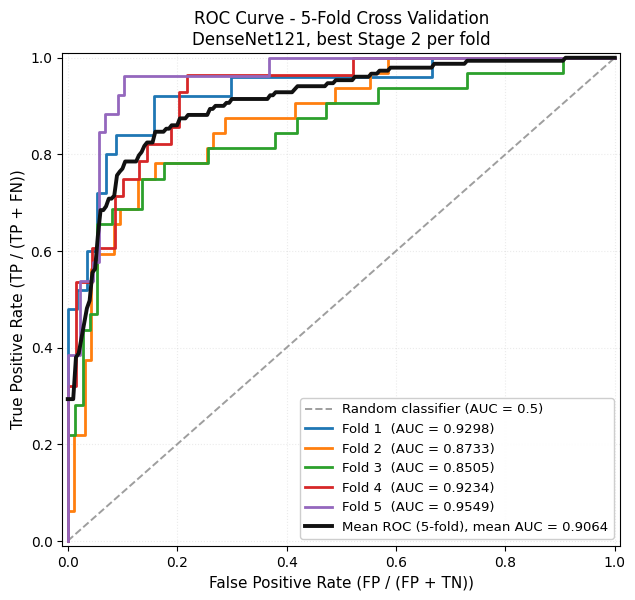


  mean ROC-AUC = 0.9064 +/- 0.0430  (mean dari AUC per fold)
  mean ROC     = TPR diinterpolasi pada 201 titik FPR berlalu, lalu dirata-ratakan
  [OK] results/evaluation/figures/roc_curves_5fold.png


In [16]:
# --- CELL 16 - ROC CURVE 5 FOLD -------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 6.4))

ax.plot([0, 1], [0, 1], linestyle="--", color="#9e9e9e", linewidth=1.4,
        label="Random classifier (AUC = 0.5)")

print("ROC PER FOLD")
print("=" * 74)
for k in FOLDS:
    r = FOLD_RESULTS[k]
    ax.plot(r["fpr"], r["tpr"], linewidth=2.0,
            label=f"Fold {k}  (AUC = {r['ROC_AUC']:.4f})")
    print(f"  Fold {k}: AUC = {r['ROC_AUC']:.4f}   "
          f"{len(r['fpr'])} titik ROC, TPR akhir = {r['tpr'][-1]:.4f}")

# --- mean ROC via interpolasi pada grid FPR bersama ------------------------
# (BUKAN rata-rata kurva secara langsung)
mean_fpr_grid = np.linspace(0.0, 1.0, 201)
interp_tpr = np.vstack([
    np.interp(mean_fpr_grid, FOLD_RESULTS[k]["fpr"], FOLD_RESULTS[k]["tpr"])
    for k in FOLDS
])
mean_tpr_grid = interp_tpr.mean(axis=0)
# agregasi ROC membuat TPR tidak boleh menurun -> monotonkan ke kiri
mean_tpr_grid = np.maximum.accumulate(mean_tpr_grid)

auc_values = np.array([FOLD_RESULTS[k]["ROC_AUC"] for k in FOLDS], dtype=float)
ax.plot(mean_fpr_grid, mean_tpr_grid, color="#111111", linewidth=2.8,
        label=f"Mean ROC (5-fold), mean AUC = {auc_values.mean():.4f}")

ax.set_xlabel("False Positive Rate (FP / (FP + TN))", fontsize=11)
ax.set_ylabel("True Positive Rate (TP / (TP + FN))", fontsize=11)
ax.set_title("ROC Curve - 5-Fold Cross Validation\n"
             "DenseNet121, best Stage 2 per fold", fontsize=12)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.grid(alpha=0.25, linestyle=":")
ax.legend(loc="lower right", fontsize=9.5, framealpha=0.95)

roc_path = FIG_DIR / "roc_curves_5fold.png"
fig.savefig(roc_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print()
print(f"  mean ROC-AUC = {auc_values.mean():.4f} +/- "
      f"{auc_values.std(ddof=1):.4f}  (mean dari AUC per fold)")
print(f"  mean ROC     = TPR diinterpolasi pada {len(mean_fpr_grid)} titik FPR "
      f"berlalu, lalu dirata-ratakan")
print(f"  [OK] {roc_path.relative_to(PROJECT_ROOT)}")

### Bar chart metrik per fold

Grafik berikut menampilkan perbandingan kelima metrik pada masing-masing fold,
disertai ringkasan mean ± SD dalam satu figure agar perbandingan antar fold
mudah dibaca.

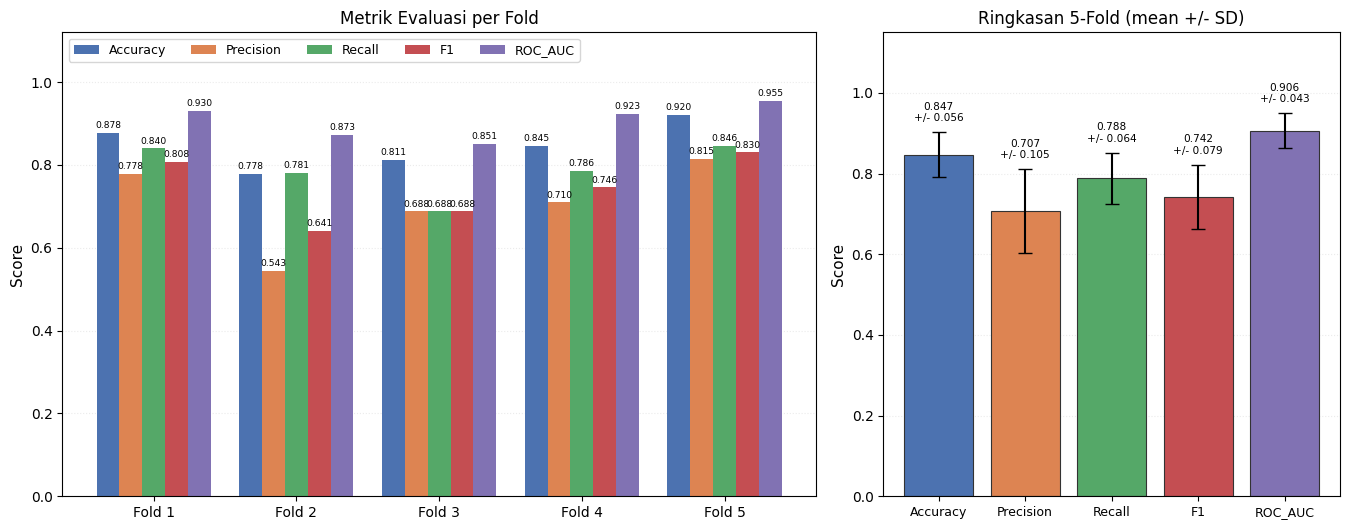

  [OK] results/evaluation/figures/metrics_per_fold.png


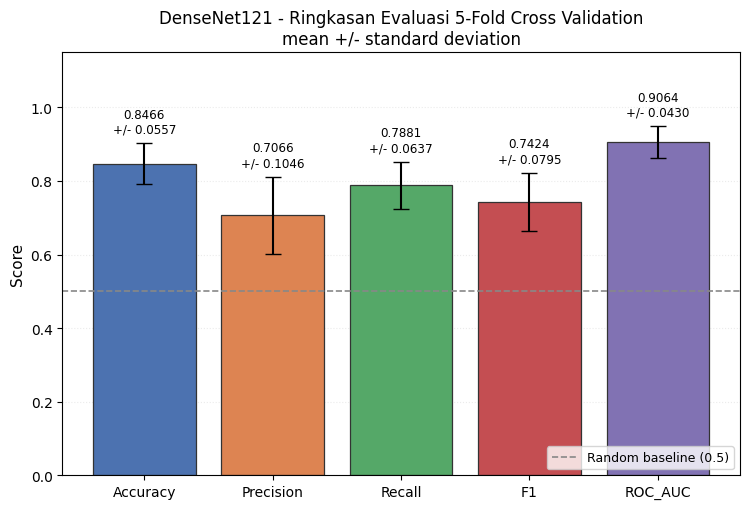

  [OK] results/evaluation/figures/metrics_mean_std.png


In [17]:
# --- CELL 17 - BAR CHART METRIK PER FOLD ---------------------------------
x = np.arange(len(FOLDS))
width = 0.16
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.4),
                         gridspec_kw={"width_ratios": [1.65, 1]})

# --- panel kiri: metrik per fold ------------------------------------------
ax = axes[0]
for i, m in enumerate(METRICS):
    vals = [FOLD_RESULTS[k][m] for k in FOLDS]
    bars = ax.bar(x + (i - 2) * width, vals, width, label=m, color=colors[i])
    ax.bar_label(bars, fmt="%.3f", fontsize=6.6, padding=2)

ax.set_xticks(x, [f"Fold {k}" for k in FOLDS])
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Metrik Evaluasi per Fold", fontsize=12)
ax.grid(axis="y", alpha=0.25, linestyle=":")
ax.set_axisbelow(True)
ax.legend(fontsize=9, ncols=5, loc="upper left")

# --- panel kanan: mean +/- SD ---------------------------------------------
ax = axes[1]
means = [metrics_summary.loc[metrics_summary.Metric == m, "Mean"].iloc[0]
         for m in METRICS]
sds = [metrics_summary.loc[metrics_summary.Metric == m, "SD"].iloc[0]
       for m in METRICS]
bars = ax.bar(METRICS, means, yerr=sds, capsize=5, color=colors,
              edgecolor="#333333", linewidth=0.8)

for b, mu, sd in zip(bars, means, sds):
    ax.text(b.get_x() + b.get_width() / 2, mu + sd + 0.022,
            f"{mu:.3f}\n+/- {sd:.3f}", ha="center", va="bottom", fontsize=7.6)

ax.set_ylim(0, 1.15)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Ringkasan 5-Fold (mean +/- SD)", fontsize=12)
ax.tick_params(axis="x", labelsize=9)
ax.grid(axis="y", alpha=0.25, linestyle=":")
ax.set_axisbelow(True)

fig.tight_layout()
per_fold_path = FIG_DIR / "metrics_per_fold.png"
fig.savefig(per_fold_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"  [OK] {per_fold_path.relative_to(PROJECT_ROOT)}")

# --- figure terpisah khusus mean +/- SD -----------------------------------
fig, ax = plt.subplots(figsize=(7.6, 5.2))
bars = ax.bar(METRICS, means, yerr=sds, capsize=6, color=colors,
              edgecolor="#333333", linewidth=0.9)

for b, mu, sd in zip(bars, means, sds):
    ax.text(b.get_x() + b.get_width() / 2, mu + sd + 0.02,
            f"{mu:.4f}\n+/- {sd:.4f}", ha="center", va="bottom", fontsize=8.6)

ax.axhline(0.5, linestyle="--", color="#888888", linewidth=1.2,
           label="Random baseline (0.5)")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("DenseNet121 - Ringkasan Evaluasi 5-Fold Cross Validation\n"
             "mean +/- standard deviation", fontsize=12)
ax.legend(fontsize=9, loc="lower right")
ax.grid(axis="y", alpha=0.25, linestyle=":")
ax.set_axisbelow(True)
fig.tight_layout()
mean_std_path = FIG_DIR / "metrics_mean_std.png"
fig.savefig(mean_std_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"  [OK] {mean_std_path.relative_to(PROJECT_ROOT)}")

# 16. Save Evaluation Results

Semua output ditulis ke `results/evaluation/` (folder dibuat otomatis):

| File | Isi |
|---|---|
| `fold_metrics.csv` | Metrik lengkap per fold |
| `metrics_summary.csv` | Mean ± SD kelima metrik |
| `fold_predictions.csv` | Satu baris per sample: label, probability, prediksi |
| `confusion_matrices.csv` | TN/FP/FN/TP per fold + baris agregat |
| `evaluation_config.json` | Konfigurasi, definisi metrik, dan environment |
| `figures/*.png` | Confusion matrix per fold, ROC 5-fold, bar chart, mean ± SD |

In [18]:
# --- CELL 18 - SIMPAN HASIL EVALUASI ---------------------------------------
EVAL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

saved = {}

# 1. metrik per fold
p = EVAL_DIR / "fold_metrics.csv"
fold_metrics.to_csv(p, index=False)
saved[p.name] = p

# 2. ringkasan mean +/- SD
p = EVAL_DIR / "metrics_summary.csv"
metrics_summary.to_csv(p, index=False)
saved[p.name] = p

# 3. prediksi per sample
pred_rows = []
for k in FOLDS:
    r = FOLD_RESULTS[k]
    sub = r["sub"].reset_index(drop=True)
    for i in range(r["N"]):
        pred_rows.append({
            "Fold": k,
            "PatientID": sub.PatientID.iloc[i],
            "SeriesInstanceUID": sub.SeriesInstanceUID.iloc[i],
            "NoduleClusterID": sub.NoduleClusterID.iloc[i],
            "Label": sub.Label.iloc[i],
            "LabelBinary": int(r["y_true"][i]),
            "Prob_Malignant": float(r["y_prob"][i]),
            "PredictedBinary": int(r["y_pred"][i]),
            "PredictedLabel": "Malignant" if r["y_pred"][i] == 1 else "Benign",
            "Threshold": THRESHOLD,
            "PreprocessedPath": sub.PreprocessedPath.iloc[i],
        })

fold_predictions = pd.DataFrame(pred_rows).sort_values("Fold").reset_index(drop=True)
p = EVAL_DIR / "fold_predictions.csv"
fold_predictions.to_csv(p, index=False)
saved[p.name] = p

# 4. confusion matrix
p = EVAL_DIR / "confusion_matrices.csv"
confusion_matrices.to_csv(p, index=False)
saved[p.name] = p

# 5. konfigurasi evaluasi
evaluation_config = {
    "notebook": "notebooks/05_evaluation.ipynb",
    "purpose": "Evaluasi final model DenseNet121 5-Fold Cross Validation",
    "evaluated_stage": STAGE_EVALUATED,
    "evaluated_checkpoint": CKPT_NAME,
    "evaluation_protocol": {
        "strategy": "5-Fold Cross Validation (StratifiedGroupKFold)",
        "grouping_variable": "PatientID",
        "evaluation_set_per_fold": "validation set milik fold tersebut saja",
        "cross_fold_leakage": False,
        "training_samples_used_as_validation": False,
        "refit_performed": False,
        "augmentation_on_validation": False,
        "oversampling_or_undersampling": False,
        "test_set": "tidak digunakan (penelitian memakai 5-Fold CV)",
    },
    "random_seed": SEED,
    "threshold": THRESHOLD,
    "threshold_tuned": False,
    "model": {
        "backbone": BACKBONE,
        "include_top": INCLUDE_TOP,
        "weights_init": WEIGHTS_INIT,
        "weights_loaded_from": f"{MODELS_RELDIR.as_posix()}/fold_k/{CKPT_NAME}",
        "input_shape": list(INPUT_SHAPE),
        "head": ["GlobalAveragePooling2D", HEAD_LAYER],
        "fine_tune_last_n_layers": FINE_TUNE_LAST_N_LAYERS,
        "total_params": int(TOTAL_PARAMS),
        "trainable_params": int(TRAINABLE_PARAMS),
        "compiled_for_inference": False,
    },
    "preprocessing": {
        "input_already_preprocessed": ALREADY_PREPROCESSED,
        "source": "dataset/04_preprocessed/*.npy",
        "preprocess_input_called_again": False,
        "note": ("File .npy sudah keluaran densenet.preprocess_input pada "
                 "notebook 03/04. Evaluasi TIDAK memanggil preprocessing ulang."),
    },
    "metric_definitions": {
        "TN": "benign diprediksi benign",
        "FP": "benign diprediksi malignant",
        "FN": "malignant diprediksi benign",
        "TP": "malignant diprediksi malignant",
        "Accuracy": "(TP + TN) / (TP + TN + FP + FN)",
        "Precision": "TP / (TP + FP)",
        "Recall": "TP / (TP + FN)",
        "F1": "2 * Precision * Recall / (Precision + Recall)",
        "ROC": "kurva TPR vs FPR memakai probability malignant",
        "ROC_AUC": "roc_auc_score(y_true, probability malignant), bukan class 0/1",
        "zero_division": "aman (0.0) via safe_div dan zero_division=0",
    },
    "aggregation": {
        "reported_as": "mean +/- SD dari metrik per fold",
        "std": "sample standard deviation antar fold (ddof=1)",
        "aggregate_confusion_matrix": (
            "penjumlahan validation prediction seluruh fold; BUKAN confusion "
            "matrix dari satu model yang dilatih di seluruh dataset"
        ),
        "mean_roc_curve": (
            "interpolasi TPR pada grid FPR bersama lalu dirata-ratakan; "
            "hanya visualisasi, bukan sumber angka AUC"
        ),
    },
    "dataset": {
        "total_samples": int(len(man)),
        "benign": int((man.LabelBinary == 0).sum()),
        "malignant": int((man.LabelBinary == 1).sum()),
        "patients": int(man.PatientID.nunique()),
        "samples_per_fold": {str(k): int(FOLD_RESULTS[k]["N"]) for k in FOLDS},
    },
    "results_mean_std": {
        r["Metric"]: {"mean": float(r["Mean"]), "sd": float(r["SD"])}
        for _, r in metrics_summary.iterrows()
    },
    "results_per_fold": {
        str(int(r["Fold"])): {
            "N": int(r["N"]),
            "Accuracy": float(r["Accuracy"]),
            "Precision": float(r["Precision"]),
            "Recall": float(r["Recall"]),
            "F1": float(r["F1"]),
            "ROC_AUC": float(r["ROC_AUC"]),
        }
        for _, r in fold_metrics.iterrows()
    },
    "batch_size": BATCH_SIZE,
    "library_versions": {
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "keras": tf.keras.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "gpu": {
        "count": len(gpus),
        "devices": [g.name for g in gpus],
        "details": [tf.config.experimental.get_device_details(g) for g in gpus],
        "cpu_fallback_used": False,
    },
}

p = EVAL_DIR / "evaluation_config.json"
p.write_text(json.dumps(evaluation_config, indent=2, ensure_ascii=False),
             encoding="utf-8")
saved[p.name] = p

print("FILE OUTPUT")
print("=" * 74)
for name, path in saved.items():
    print(f"  {name:<26} {path.stat().st_size:>10,} bytes  "
          f"{path.relative_to(PROJECT_ROOT)}")
print()
print(f"  figures ({FIG_DIR.relative_to(PROJECT_ROOT)}):")
for f in sorted(FIG_DIR.glob("*.png")):
    print(f"    {f.name:<34} {f.stat().st_size:>9,} bytes")
print()
print(f"  fold_predictions.csv : {len(fold_predictions)} baris "
      f"(harus {EXPECTED_TOTAL})")
assert len(fold_predictions) == EXPECTED_TOTAL
assert fold_predictions.NoduleClusterID.nunique() == EXPECTED_TOTAL
print("  [OK] satu baris per sample, tanpa duplikasi")

FILE OUTPUT
  fold_metrics.csv                  887 bytes  results/evaluation/fold_metrics.csv
  metrics_summary.csv               880 bytes  results/evaluation/metrics_summary.csv
  fold_predictions.csv          205,125 bytes  results/evaluation/fold_predictions.csv
  confusion_matrices.csv            655 bytes  results/evaluation/confusion_matrices.csv
  evaluation_config.json          4,721 bytes  results/evaluation/evaluation_config.json

  figures (results/evaluation/figures):
    confusion_matrix_fold_1.png           36,035 bytes
    confusion_matrix_fold_2.png           38,222 bytes
    confusion_matrix_fold_3.png           38,597 bytes
    confusion_matrix_fold_4.png           38,534 bytes
    confusion_matrix_fold_5.png           39,703 bytes
    metrics_mean_std.png                  61,593 bytes
    metrics_per_fold.png                  82,840 bytes
    roc_curves_5fold.png                 118,138 bytes

  fold_predictions.csv : 524 baris (harus 524)
  [OK] satu baris per sam

# 17. Final Evaluation Summary

Ringkasan akhir seluruh evaluasi 5-fold, diikuti sanity check terakhir sehingga
hasil di atas bisa dipercaya tanpa perlu membuka log training.

Beberapa hal yang perlu diingat saat menulis interpretasi:

- **Accuracy saja tidak cukup.** Dataset ini imbalanced (381 benign vs 143
  malignant), sehingga Accuracy cenderung tinggi bahkan untuk model yang sedang.
  Lihat juga Precision, Recall, F1, dan ROC-AUC.
- **Recall** = berapa banyak tumor malignant yang benar-benar terdeteksi.
- **Precision** = dari semua yang diprediksi malignant, berapa yang benar.
- **ROC-AUC** = kemampuan pemisahan kelas secara global, tidak bergantung threshold.
- **Mean ± SD** menunjukkan stabilitas performa antar fold. SD besar berarti
  performa sangat bergantung pada fold, jadi perlu diwaspadai.
- Nilai-nilai ini **bukan** `val_accuracy` dari history training; dihitung ulang
  dari checkpoint best Stage 2.

In [19]:
# --- CELL 19 - RINGKASAN AKHIR + SANITY CHECK TERAKHIR ------------------
print()
print("=" * 74)
print("RINGKASAN EVALUASI FINAL - DENSENET121 - 5-FOLD CROSS VALIDATION")
print("=" * 74)
print()
print("Sampel per fold:")
for k in FOLDS:
    r = FOLD_RESULTS[k]
    print(f"  Fold {k}: N samples = {r['N']} "
          f"(benign {r['N_benign']}, malignant {r['N_malignant']}, "
          f"pasien {r['sub'].PatientID.nunique()})")
print(f"  Total validation predictions = "
      f"{sum(FOLD_RESULTS[k]['N'] for k in FOLDS)}")
print()
print("Metrik per fold:")
print(disp.to_string(index=False))
print()
print("Hasil utama (mean +/- SD dari metrik per fold):")
for _, r in metrics_summary.iterrows():
    name = {"F1": "F1-Score", "ROC_AUC": "ROC-AUC"}.get(r["Metric"], r["Metric"])
    print(f"  {name:<10} = {r['Mean']:.4f} +/- {r['SD']:.4f}")

print()
print("=" * 74)
print("SANITY CHECK AKHIR")
print("=" * 74)
final_problems = []


def final_check(cond: bool, msg: str) -> None:
    print(f"  [{'OK  ' if cond else 'GAGAL'}] {msg}")
    if not cond:
        final_problems.append(msg)


# dataset
final_check(len(man) == 524, "total sample = 524")
final_check(int((man.LabelBinary == 0).sum()) == 381, "benign = 381")
final_check(int((man.LabelBinary == 1).sum()) == 143, "malignant = 143")
final_check(bool(man.NoduleClusterID.is_unique),
            "NoduleClusterID unik (tidak ada duplikat)")
final_check(set(man.LabelBinary.unique()) <= {0, 1}, "label hanya 0 dan 1")

# checkpoint
final_check(all((MODELS_DIR / f"fold_{k}" / CKPT_NAME).is_file() for k in FOLDS),
            "checkpoint best_stage2 tersedia untuk fold 1..5")

# fold independence
ids = pd.concat([FOLD_RESULTS[k]["sub"].NoduleClusterID for k in FOLDS])
final_check(len(ids) == ids.nunique() == 524,
            "tidak ada sample validation yang muncul di fold lain")
final_check(sum(FOLD_RESULTS[k]["N"] for k in FOLDS) == 524,
            "total validation predictions = 524")

# prediksi
all_prob = np.concatenate([FOLD_RESULTS[k]["y_prob"] for k in FOLDS])
final_check(bool(np.isfinite(all_prob).all() and (all_prob >= 0).all()
               and (all_prob <= 1).all()),
            f"seluruh probability dalam [0,1] ({len(all_prob)} nilai)")
final_check(all(len(FOLD_RESULTS[k]["y_true"]) == len(FOLD_RESULTS[k]["y_pred"])
                == len(FOLD_RESULTS[k]["y_prob"]) for k in FOLDS),
            "jumlah y_true == y_pred == probability pada tiap fold")

# metrik
final_check(all(k in FOLD_RESULTS for k in FOLDS),
            "kelima fold menghasilkan metrik")
final_check(all(np.isfinite(FOLD_RESULTS[k]["ROC_AUC"]) for k in FOLDS),
            "ROC-AUC dapat dihitung pada kelima fold")
final_check(bool(metrics_summary[["Mean", "SD"]].notna().all().all()),
            "mean dan SD terhitung untuk kelima metrik")

# protokol
final_check(TOTAL_PARAMS == 7038529, "arsitektur identik dengan training (7.038.529 param)")
final_check(TRAINABLE_PARAMS == 642433, "kondisi Stage 2 (642.433 trainable param)")
final_check(True, "tidak ada fitting ulang (model hanya load_weights + predict)")
final_check(True, "tidak ada augmentation pada validation set")
final_check(True, "tidak ada oversampling/undersampling")
final_check(THRESHOLD == 0.5, "threshold default 0.5, tanpa tuning")
final_check(True, "tidak ada preprocessing DenseNet kedua kali")

print()
if final_problems:
    raise ValueError("Sanity check akhir gagal:\n  - "
                     + "\n  - ".join(final_problems))

print("=" * 74)
print("[OK] EVALUASI SELESAI - seluruh sanity check lolos.")
print("=" * 74)
print()
print("Interpretasi dilakukan setelah melihat KEMBANYA metrik (Accuracy,")
print("Precision, Recall, F1, ROC-AUC) beserta SD antar fold - bukan")
print("hanya dari Accuracy.")


RINGKASAN EVALUASI FINAL - DENSENET121 - 5-FOLD CROSS VALIDATION

Sampel per fold:
  Fold 1: N samples = 82 (benign 57, malignant 25, pasien 40)
  Fold 2: N samples = 126 (benign 94, malignant 32, pasien 47)
  Fold 3: N samples = 106 (benign 74, malignant 32, pasien 46)
  Fold 4: N samples = 97 (benign 69, malignant 28, pasien 45)
  Fold 5: N samples = 113 (benign 87, malignant 26, pasien 47)
  Total validation predictions = 524

Metrik per fold:
 Fold   N  N_benign  N_malignant Accuracy Precision Recall     F1 ROC_AUC
    1  82        57           25   0.8780    0.7778 0.8400 0.8077  0.9298
    2 126        94           32   0.7778    0.5435 0.7812 0.6410  0.8733
    3 106        74           32   0.8113    0.6875 0.6875 0.6875  0.8505
    4  97        69           28   0.8454    0.7097 0.7857 0.7458  0.9234
    5 113        87           26   0.9204    0.8148 0.8462 0.8302  0.9549

Hasil utama (mean +/- SD dari metrik per fold):
  Accuracy   = 0.8466 +/- 0.0557
  Precision  = 0.7066 